In [1]:
import pandas as pd

from pipeline import get_feature_names, get_target_name, build_model_pipeline
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split)
from sklearn.linear_model import (
    LogisticRegression
    )
from sklearn.ensemble import (
    RandomForestClassifier
    )
from sklearn.neural_network import(
    MLPClassifier
    )

import data_loader
import evaluation 

## TESTING
import importlib

PATH_DATA ='data/raw/Telco_customer_churn.xlsx'
SEED = 4586

target_recall=0.8
min_precision=0.65

generic_colors : list[str] = [ "#0000ff", "#f63400", "#9d02d7", "#ff6ecd", "#9b0000" ]
evaluation.set_color_cycle(generic_colors)



In [2]:
df = data_loader.load_churn_data(PATH_DATA)

X = df[get_feature_names(False)]
y = df[get_target_name(False)]

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=SEED, stratify=y)
y_test.value_counts()

Churn Value
0    1294
1     467
Name: count, dtype: int64

In [3]:
pipeline_lr = build_model_pipeline(
        LogisticRegression(),
        scale=True
    )

pipeline_rfc = build_model_pipeline(
        RandomForestClassifier(),
        scale=False
    )

pipeline_mlp = build_model_pipeline(
        MLPClassifier(),
        scale=True
    )


models = {
    'lr':pipeline_lr,
    'rfc':pipeline_rfc,
    'mlp':pipeline_mlp
}

models_grid_params = {
    'lr':{
        'param_grid':{
            'model__solver': ['saga'],
            'model__l1_ratio': [0, 0.25, 0.5, 0.75, 1],  # 0 = pure L2, 1 = pure L1
            'model__C': [0.1, 1.0, 10.0],
            'model__max_iter': [1000],  # Increased so saga converges cleanly
            'model__class_weight':['balanced'],
            'model__random_state':[SEED]
            },
        'scoring':'average_precision',
        'n_iter':20
        },
    'rfc':{
       'param_grid':{
           'model__random_state':[SEED],
           'model__n_estimators': [100, 250, 500],
           'model__max_features': ['sqrt', 'log2'],
           'model__max_depth':[10, 20, 30],
           'model__min_samples_leaf':[3, 7],
           'model__min_samples_split': [2, 5, 10],
            'model__class_weight': ['balanced', 'balanced_subsample'],
           },
        'scoring':'average_precision' ,
        'n_iter':40
        },
    'mlp':{
        'param_grid':{
           'model__random_state':[SEED],
            'model__hidden_layer_sizes':[(32,), (64, 32), (16,)],
            'model__activation':['relu', 'tanh'],
            'model__solver':['adam'],
            'model__alpha':[0.0001, 0.05, 0.1],
            'model__learning_rate_init':[0.001, 0.01],
            'model__max_iter':[300, 500],
            'model__early_stopping':[True],
            'model__validation_fraction':[0.15]
            },
        'scoring':'average_precision' ,
        'n_iter':40
        }
    }

In [4]:
grid_results = evaluation.random_grid_search_models(
        models = models,
        models_grid_params=models_grid_params,
        X_train=X_train,
        y_train=y_train,
        X_test=X_test,
        seed=SEED,
    )

d:\_FIAP\01_MachineLearning\01_Fase1\00_Tech Challenge\fiap-ml-techchallenge1\.venv\Lib\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 15 is smaller than n_iter=20. Running 15 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


In [5]:
evaluation.add_stats_to_grid_results(
    grid_results=grid_results,
    X_train=X_train,
    y_train=y_train,
    y_test=y_test,
    target_recall=target_recall,
    seed=SEED
)

grid_results

{'lr': {'grid_search': RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=4586, shuffle=True),
                     estimator=Pipeline(steps=[('preprocessing',
                                                Pipeline(steps=[('format column '
                                                                 'names',
                                                                 ColumnNameFormatter()),
                                                                ('filter columns',
                                                                 ColumnTransformer(transformers=[('keep',
                                                                                                  'passthrough',
                                                                                                  ['tenure_months',
                                                                                                   'monthly_charges',
                                               

In [6]:
evaluation.display_grid_results(grid_results)

RESULTS FOR "lr"
Best Parameters: {'model__solver': 'saga', 'model__random_state': 4586, 'model__max_iter': 1000, 'model__l1_ratio': 0, 'model__class_weight': 'balanced', 'model__C': 10.0}
Best CV average_precision: 0.6731
Threshold ( Recall on Test = 0.80 | Precision on Test = 0.54 ) = 0.50
RESULTS FOR "rfc"
Best Parameters: {'model__random_state': 4586, 'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 7, 'model__max_features': 'log2', 'model__max_depth': 10, 'model__class_weight': 'balanced'}
Best CV average_precision: 0.6867
Threshold ( Recall on Test = 0.82 | Precision on Test = 0.54 ) = 0.49
RESULTS FOR "mlp"
Best Parameters: {'model__validation_fraction': 0.15, 'model__solver': 'adam', 'model__random_state': 4586, 'model__max_iter': 300, 'model__learning_rate_init': 0.01, 'model__hidden_layer_sizes': (32,), 'model__early_stopping': True, 'model__alpha': 0.1, 'model__activation': 'relu'}
Best CV average_precision: 0.6780
Threshold ( Recall on T

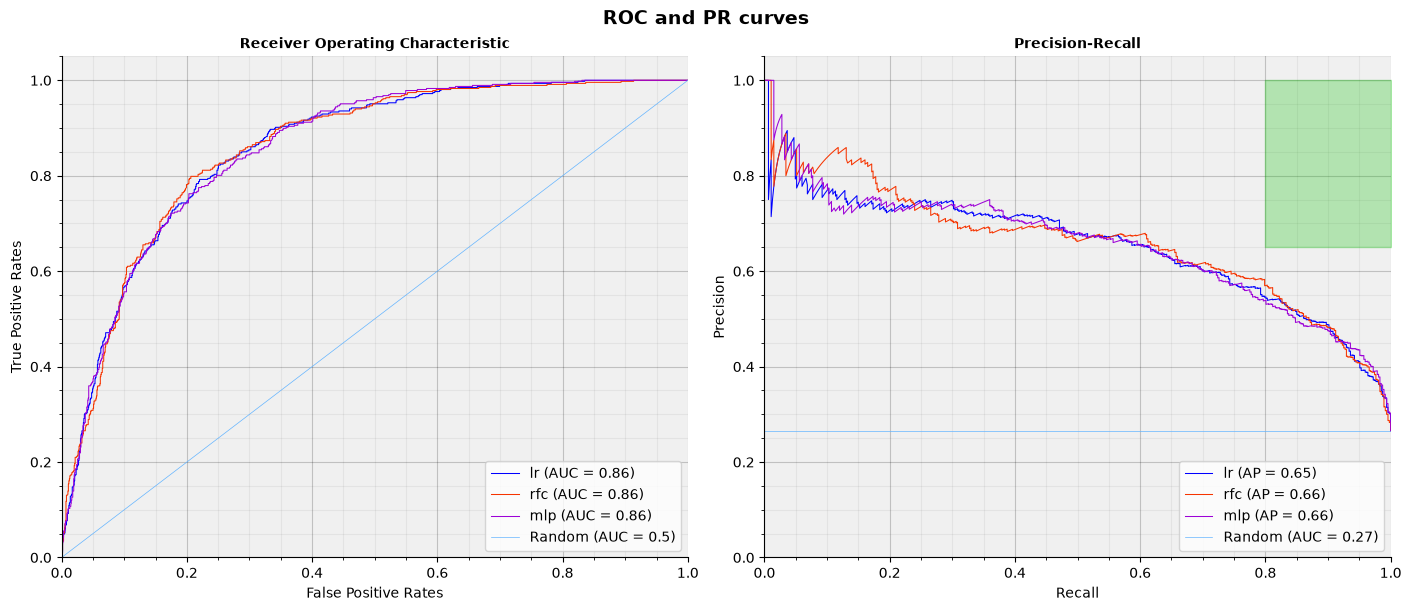

In [7]:
evaluation.plot_multiple_roc_pr(
    y_true=y_test,
    results=grid_results,
    target_recall=target_recall,
    min_precision=min_precision,
    figsize=(14,6)
)
plt.show()

In [8]:
for model in grid_results:
    evaluation.quick_evaluation(y_test, grid_results[model]['y_proba'], grid_results[model]['stats']['threshold'], model)

EVALUATION OF LR AT THRESHOLD 0.4981689174156193
              precision    recall  f1-score   support

           0       0.91      0.76      0.83      1294
           1       0.54      0.80      0.65       467

    accuracy                           0.77      1761
   macro avg       0.73      0.78      0.74      1761
weighted avg       0.82      0.77      0.78      1761

acc			0.77
recall			0.80
precision		0.54
f1-score		0.65
average precision	0.65
EVALUATION OF RFC AT THRESHOLD 0.4900254162550497
              precision    recall  f1-score   support

           0       0.92      0.75      0.83      1294
           1       0.54      0.82      0.65       467

    accuracy                           0.77      1761
   macro avg       0.73      0.79      0.74      1761
weighted avg       0.82      0.77      0.78      1761

acc			0.77
recall			0.82
precision		0.54
f1-score		0.65
average precision	0.66
EVALUATION OF MLP AT THRESHOLD 0.2589661824441823
              precision    recall  f1-s

In [ ]:
# move to function in .evaluation
pd.DataFrame({name: results['stats'] for name, results in grid_results.items()}).T

,threshold,recall,precision,cv_ap_mean,cv_ap_std,recall_on_test,precision_on_test
lr,0.498169,0.800285,0.516575,0.673144,0.032533,0.802998,0.543478
rfc,0.490025,0.800285,0.533524,0.686736,0.023228,0.824411,0.542254
mlp,0.258966,0.800285,0.520167,0.677972,0.033232,0.843683,0.507732


: 